# Exploring crop yield across Indian regions

Can rainfall, agricultural inputs, temperature and humidity help predict crop yield beyond what we already know from past yields? This notebook checks the data, explores patterns, tests two crop examples, and then compares prediction methods across many crop and region combinations.

Yield is the outcome we want to predict; it describes crop output relative to cultivated area. The source's yield units should be confirmed before quoting physical quantities, and yields for different crops should not be compared directly. An input or *feature* is a measurement used to make a prediction, and a *baseline* is a simple method that a more complex model should improve upon.

Run the cells from top to bottom, with this notebook's folder as the working directory. The crop file is in `data/raw`, and saved weather responses are in `data/external`; an internet connection is needed for package installation and for any missing weather files. Exploration and modelling use records through 2014; later crop records are outside the evaluation reported here.

## 1. Prepare and check the data

### 1.1 Install the required packages

The next cell installs the packages listed in `requirements.txt` into the notebook's Python environment. Run it when setting up the project; if packages are updated, restart the kernel before continuing.

In [101]:
# Install required libraries

%pip install -r requirements.txt

  Using cached ipykernel-6.29.5-py3-none-any.whl.metadata (6.3 kB)
Using cached ipykernel-6.29.5-py3-none-any.whl (117 kB)
  Attempting uninstall: ipykernel
    Found existing installation: ipykernel 7.3.0
    Uninstalling ipykernel-7.3.0:
      Successfully uninstalled ipykernel-7.3.0
Note: you may need to restart the kernel to use updated packages.


c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedWriter name=5>
  res = process_handler(cmd, _system_body)
c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=6>
  res = process_handler(cmd, _system_body)
c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=7>
  res = process_handler(cmd, _system_body)


### 1.2 Load the analysis tools

The next cell loads tools for organising tables, drawing charts and fitting prediction models. It also loads the scoring functions used later to compare predictions with observed yields.

In [102]:
# Load dependencies

from pathlib import Path

# data handling
import numpy as np
import pandas as pd

# visualisation, graphs
import matplotlib.pyplot as plt
import seaborn as sns

# data preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Comparison models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

# Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)



from scipy import stats

from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline


### 1.3 Inspect the original crop records

Before changing the data, we inspect sample rows, column types, missing values and exact duplicates. These checks reveal obvious data-quality issues, but cannot establish that every recorded value is correct.

In [103]:

data_path = Path("data") / "raw" / "BronzeLayer_data.csv"
df = pd.read_csv(data_path)

print(df.head())
print(df.shape)
df.info()

print("\nMissing values:")
print(df.isna().sum())

print("\nExact duplicate rows:")
print(df.duplicated().sum())

print("\nNumeric summary:")
print(df.describe())

           Crop  Crop_Year       Season  State     Area  Production  \
0      Arecanut       1997  Whole Year   Assam  73814.0       56708   
1     Arhar/Tur       1997  Kharif       Assam   6637.0        4685   
2   Castor seed       1997  Kharif       Assam    796.0          22   
3      Coconut        1997  Whole Year   Assam  19656.0   126905000   
4  Cotton(lint)       1997  Kharif       Assam   1739.0         794   

   Annual_Rainfall  Fertilizer  Pesticide        Yield  
0           2051.4  7024878.38   22882.34     0.796087  
1           2051.4   631643.29    2057.47     0.710435  
2           2051.4    75755.32     246.76     0.238333  
3           2051.4  1870661.52    6093.36  5238.051739  
4           2051.4   165500.63     539.09     0.420909  
(19689, 10)
<class 'pandas.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 n

### 1.4 Group states into three regions

The initial inspection reports 19,689 records, with no missing values or exact duplicate rows. The next cell assigns states to South, North West Central, or East Northeast so that crop patterns can be compared in broader groups. These are groupings chosen for this analysis, and the coverage check ensures every recorded state receives a region.

In [104]:
regions = {
    "North_West_Central": [
        "Punjab", "Haryana", "Himachal Pradesh", "Jammu and Kashmir",
        "Delhi", "Uttarakhand", "Uttar Pradesh", "Rajasthan",
        "Gujarat", "Maharashtra", "Goa", "Madhya Pradesh", "Chhattisgarh"
    ],
    "East_Northeast": [
        "Bihar", "Jharkhand", "Odisha", "West Bengal", "Assam",
        "Arunachal Pradesh", "Manipur", "Meghalaya", "Mizoram",
        "Nagaland", "Sikkim", "Tripura"
    ],
    "South": [
        "Andhra Pradesh", "Telangana", "Karnataka",
        "Kerala", "Tamil Nadu", "Puducherry"
    ]
}

state_to_region = {
    state: region
    for region, states in regions.items()
    for state in states
}

df["Region"] = df["State"].map(state_to_region)

assert df["Region"].notna().all(), "Some states have no region mapping."

df["Region"].value_counts()

Region
North_West_Central    7660
East_Northeast        6908
South                 5121
Name: count, dtype: int64

## 2. Explore coverage and relationships

### 2.1 Count the crops represented in each region

The next cell restricts exploration to years through 2014 and counts records, states and crops by region. It also shows how many records exist for each crop and region; a zero means no observations in this subset, rather than proof that the crop is never grown there. Record counts describe dataset coverage, rather than planted area or total production.

In [105]:
eda = df[df["Crop_Year"] <= 2014].copy()

display(eda.groupby("Region").agg(
    Records=("Crop", "size"),
    States=("State", "nunique"),
    Crops=("Crop", "nunique")
))

crop_counts = pd.crosstab(eda["Crop"], eda["Region"])
crop_counts


,Records,States,Crops
Region,,,
East_Northeast,5140,12,53
North_West_Central,5719,12,52
South,3547,6,50


Region,East_Northeast,North_West_Central,South
Crop,,,
Arecanut,44,8,70
Arhar/Tur,147,155,72
Bajra,56,210,121
Banana,64,48,74
Barley,66,160,0
Black pepper,16,12,63
Cardamom,13,0,46
Cashewnut,10,13,68
Castor seed,85,78,57


### 2.2 Compare the ten most frequently recorded crops

This chart compares regional record counts for the ten crops with the most observations overall. Differences between bars help identify uneven coverage, which matters when deciding how broadly a later result can be applied.

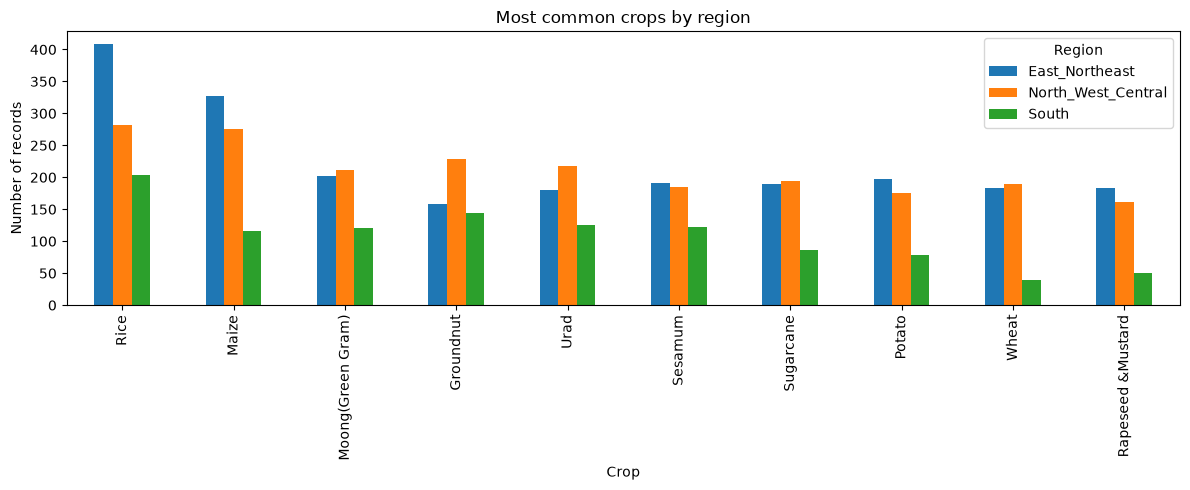

In [106]:
top_crops = eda["Crop"].value_counts().head(10).index

crop_counts.loc[top_crops].plot.bar(figsize=(12, 5))
plt.ylabel("Number of records")
plt.title("Most common crops by region")
plt.tight_layout()
plt.show()


### 2.3 Express agricultural inputs per unit of area

Larger cultivated areas can have larger total fertiliser and pesticide use simply because they are larger. The next cell divides each total by area to make the input measures more comparable across records. Zero or negative areas are treated as missing for these calculations to avoid invalid division.

In [107]:
area = df["Area"].where(df["Area"] > 0)

df["Fertilizer_per_area"] = df["Fertilizer"] / area
df["Pesticide_per_area"] = df["Pesticide"] / area

eda = df[df["Crop_Year"] <= 2014].copy()

eda[["Fertilizer_per_area", "Pesticide_per_area"]].describe()

,Fertilizer_per_area,Pesticide_per_area
count,14406.000000,14406.000000
mean,128.475229,0.244248
std,25.291912,0.062029
min,94.670000,0.090000
25%,102.130000,0.210000
50%,127.710000,0.250000
75%,150.800000,0.290000
max,167.520000,0.330000


### 2.4 Examine relationships within rice records

The next heatmap shows correlations for rice, keeping the crop fixed so that differences between crops do not dominate the comparison. Values close to +1 indicate that two measurements tend to rise together, values close to -1 indicate opposite movement, and values near zero indicate little straight-line association. Correlation alone does not show that changing an input would cause yield to change.

c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


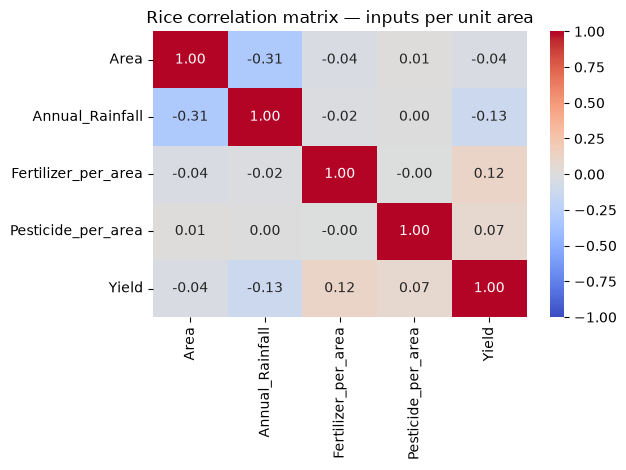

In [108]:
rice = eda[eda["Crop"] == "Rice"].copy()

columns = [
    "Area",
    "Annual_Rainfall",
    "Fertilizer_per_area",
    "Pesticide_per_area",
    "Yield"
]

sns.heatmap(
    rice[columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Rice correlation matrix — inputs per unit area")
plt.tight_layout()
plt.show()

## 3. Add temperature and humidity

### 3.1 Choose weather sampling locations

The crop table does not contain temperature or humidity, so the next section adds weather observations using one selected location per state. The following cell defines those coordinates and checks coverage. A single location is an approximation of conditions across a state and may differ from conditions at crop-growing sites.

In [109]:
state_points = {
    "Andhra Pradesh": (16.5075, 80.6466),    # Vijayawada
    "Arunachal Pradesh": (27.0869, 93.6099), # Itanagar
    "Assam": (26.1844, 91.7458),             # Guwahati
    "Bihar": (25.5941, 85.1356),             # Patna
    "Chhattisgarh": (21.2333, 81.6333),      # Raipur
    "Delhi": (28.6520, 77.2315),
    "Goa": (15.4957, 73.8262),               # Panaji
    "Gujarat": (23.0258, 72.5873),           # Ahmedabad
    "Haryana": (29.1539, 75.7229),           # Hisar
    "Himachal Pradesh": (31.1044, 77.1666),  # Shimla
    "Jammu and Kashmir": (34.0857, 74.8056), # Srinagar
    "Jharkhand": (23.3432, 85.3094),         # Ranchi
    "Karnataka": (12.9719, 77.5937),         # Bengaluru
    "Kerala": (10.5167, 76.2167),            # Thrissur
    "Madhya Pradesh": (23.2547, 77.4029),    # Bhopal
    "Maharashtra": (21.1463, 79.0849),       # Nagpur
    "Manipur": (24.8081, 93.9442),           # Imphal
    "Meghalaya": (25.5689, 91.8831),         # Shillong
    "Mizoram": (23.7289, 92.7179),           # Aizawl
    "Nagaland": (25.6747, 94.1110),          # Kohima
    "Odisha": (20.2724, 85.8339),            # Bhubaneswar
    "Puducherry": (11.9338, 79.8298),
    "Punjab": (30.9120, 75.8538),            # Ludhiana
    "Sikkim": (27.3257, 88.6122),            # Gangtok
    "Tamil Nadu": (9.9190, 78.1195),         # Madurai
    "Telangana": (18.0000, 79.5833),         # Warangal
    "Tripura": (23.8361, 91.2794),           # Agartala
    "Uttar Pradesh": (26.8393, 80.9231),     # Lucknow
    "Uttarakhand": (30.3244, 78.0339),       # Dehradun
    "West Bengal": (22.5626, 88.3630),       # Kolkata
}

# Check that every state in your dataset has coordinates
missing_states = set(df["State"]) - set(state_points)

assert not missing_states, f"Missing sampling coordinates: {sorted(missing_states)}"


### 3.2 Read the monthly weather data

The next cell reads saved NASA POWER responses, or requests them when a state's file is missing, for 1996?2021. It extracts monthly temperature in degrees Celsius and relative humidity in percent, replaces the source's missing-value marker, and saves the combined weather table. Downloaded responses are cached so later runs can reuse them.

In [110]:
import json
import time
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import urlopen

import numpy as np
import pandas as pd

folder = Path("data/external/nasa_power/t2m_rh2m_1996_2021")
folder.mkdir(parents=True, exist_ok=True)

region_lookup = (
    df[["State", "Region"]]
    .drop_duplicates()
    .set_index("State")["Region"]
    .to_dict()
)

expected_months = pd.date_range("1996-01-01", "2021-12-01", freq="MS")
tables = []

for state in sorted(df["State"].unique()):
    latitude, longitude = state_points[state]
    cache_file = folder / f"{state.replace(' ', '_')}.json"

    if cache_file.exists():
        nasa = json.loads(cache_file.read_text(encoding="utf-8"))
    else:
        parameters = {
            "parameters": "T2M,RH2M",
            "community": "AG",
            "latitude": latitude,
            "longitude": longitude,
            "start": 1996,
            "end": 2021,
            "format": "JSON"
        }

        url = (
            "https://power.larc.nasa.gov/api/temporal/monthly/point?"
            + urlencode(parameters)
        )

        with urlopen(url, timeout=120) as response:
            nasa = json.load(response)

        cache_file.write_text(json.dumps(nasa), encoding="utf-8")

        time.sleep(1)

    weather = pd.DataFrame(
        nasa["properties"]["parameter"]
    )[["T2M", "RH2M"]]

    weather.index = pd.to_datetime(
        weather.index, format="%Y%m", errors="coerce"
    )
    weather = weather.loc[weather.index.notna()].sort_index()

    weather = weather.replace(
        nasa.get("header", {}).get("fill_value", -999), np.nan
    )

    weather = weather.rename(columns={
        "T2M": "Mean_Temperature",
        "RH2M": "Relative_Humidity"
    })

    weather = weather.rename_axis("Date").reset_index()
    weather["State"] = state
    weather["Region"] = region_lookup[state]

    tables.append(weather)
    print(f"Completed: {state}")

nasa_weather = pd.concat(tables, ignore_index=True)

nasa_weather.to_csv(folder / "monthly_weather.csv", index=False)

pd.DataFrame.from_dict(
    state_points,
    orient="index",
    columns=["Latitude", "Longitude"]
).rename_axis("State").to_csv(folder / "sampling_points.csv")

nasa_weather.head()

Completed: Andhra Pradesh
Completed: Arunachal Pradesh
Completed: Assam
Completed: Bihar
Completed: Chhattisgarh
Completed: Delhi
Completed: Goa
Completed: Gujarat
Completed: Haryana
Completed: Himachal Pradesh
Completed: Jammu and Kashmir
Completed: Jharkhand
Completed: Karnataka
Completed: Kerala
Completed: Madhya Pradesh
Completed: Maharashtra
Completed: Manipur
Completed: Meghalaya
Completed: Mizoram
Completed: Nagaland
Completed: Odisha
Completed: Puducherry
Completed: Punjab
Completed: Sikkim
Completed: Tamil Nadu
Completed: Telangana
Completed: Tripura
Completed: Uttar Pradesh
Completed: Uttarakhand
Completed: West Bengal


,Date,Mean_Temperature,Relative_Humidity,State,Region
0,1996-01-01,24.18,70.07,Andhra Pradesh,South
1,1996-02-01,26.38,63.64,Andhra Pradesh,South
2,1996-03-01,30.15,55.04,Andhra Pradesh,South
3,1996-04-01,32.11,56.39,Andhra Pradesh,South
4,1996-05-01,35.08,45.32,Andhra Pradesh,South


### 3.3 Match annual weather to crop records

Monthly temperature and humidity are averaged by state and calendar year, then joined to the crop records through 2014. The assertion checks that each crop record has matching weather. The heatmap gives an overview across all crops, but mixed crop scales can hide or exaggerate relationships; annual averages also lose seasonal detail.

c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


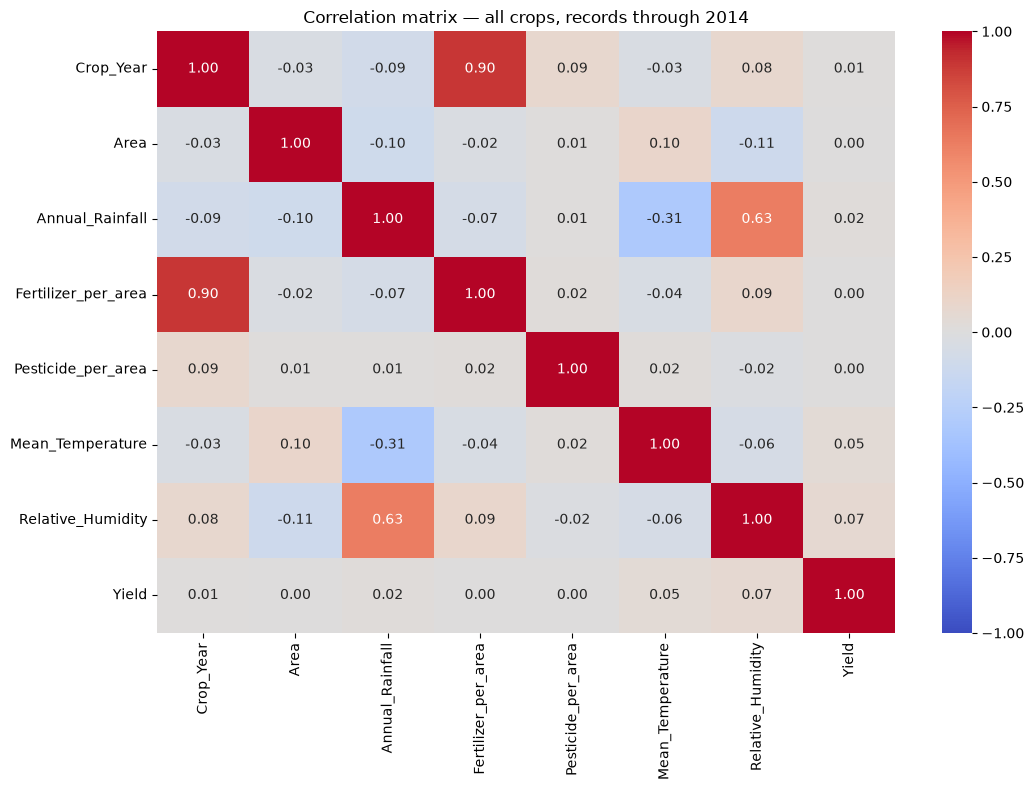

In [111]:
# Average monthly weather for each state and calendar year
annual_weather = (
    nasa_weather.assign(
        Crop_Year=nasa_weather["Date"].dt.year
    )
    .groupby(["State", "Crop_Year"])[
        ["Mean_Temperature", "Relative_Humidity"]
    ]
    .mean()
    .reset_index()
)

# Attach weather to training-period crop records
eda = df[df["Crop_Year"] <= 2014].merge(
    annual_weather,
    on=["State", "Crop_Year"],
    how="left",
    validate="many_to_one"
)

assert eda[
    ["Mean_Temperature", "Relative_Humidity"]
].notna().all().all(), "Some crop records have no matching weather."

# Correlation matrix
columns = [
    "Crop_Year",
    "Area",
    "Annual_Rainfall",
    "Fertilizer_per_area",
    "Pesticide_per_area",
    "Mean_Temperature",
    "Relative_Humidity",
    "Yield"
]

plt.figure(figsize=(11, 8))

sns.heatmap(
    eda[columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation matrix — all crops, records through 2014")
plt.tight_layout()
plt.show()

### 3.4 Find crop and region combinations worth examining

The next cell calculates input?yield correlations separately for each crop and region with at least 30 records. It lists the strongest association for each crop, keeping only its highest-ranked region in the displayed shortlist. This is an exploratory screening step: strong correlations, especially in small groups, do not guarantee useful predictions on later years.

In [112]:
features = [
    "Annual_Rainfall",
    "Fertilizer_per_area",
    "Pesticide_per_area",
    "Mean_Temperature",
    "Relative_Humidity"
]

results = []

for (region, crop), group in eda.groupby(["Region", "Crop"]):
    if len(group) >= 30:
        correlations = group[features].corrwith(group["Yield"])

        results.append({
            "Region": region,
            "Crop": crop,
            "Records": len(group),
            **correlations.to_dict()
        })

regional_correlations = pd.DataFrame(results)
regional_correlations


ranked = regional_correlations.copy()

# Strength of the strongest correlation for each region–crop pair
ranked["Strongest_Absolute_Correlation"] = ranked[features].abs().max(axis=1)

# Which feature has that correlation?
ranked["Strongest_Feature"] = ranked[features].abs().idxmax(axis=1)

# Rank strongest first
ranked = ranked.sort_values(
    "Strongest_Absolute_Correlation",
    ascending=False
)

display(
    ranked.drop_duplicates(subset="Crop")[
        ["Crop", "Region", "Records", "Strongest_Feature",
         "Strongest_Absolute_Correlation"]
    ].head(20)
)



,Crop,Region,Records,Strongest_Feature,Strongest_Absolute_Correlation
6,Coconut,East_Northeast,36,Mean_Temperature,0.909884
31,Sannhamp,East_Northeast,34,Relative_Humidity,0.897024
106,Mesta,South,43,Mean_Temperature,0.861856
98,Garlic,South,51,Annual_Rainfall,0.846985
37,Sweet potato,East_Northeast,68,Relative_Humidity,0.816103
3,Banana,East_Northeast,64,Mean_Temperature,0.792493
21,Niger seed,East_Northeast,58,Mean_Temperature,0.759842
90,Black pepper,South,63,Mean_Temperature,0.751271
84,Wheat,North_West_Central,189,Annual_Rainfall,0.749338
93,Castor seed,South,57,Mean_Temperature,0.736715


## 4. Case study: wheat in North West Central

### 4.1 Check the selected subset

Wheat in North West Central provides a focused example of moving from a correlation to a prediction model. The next cell checks its 189 records for missing inputs, unusual ranges and duplicate rows before fitting a model. This example was examined after exploring the data, so its test results should be treated as exploratory.

In [113]:
wheat = eda.loc[
    (eda["Crop"] == "Wheat") &
    (eda["Region"] == "North_West_Central")
].copy()

print("Number of records:", len(wheat))

display(wheat.head())

# Check missing values in the proposed inputs and target
display(wheat[features + ["Yield"]].isna().sum())

# Inspect ranges and identify potentially unusual values
display(wheat[features + ["Yield"]].describe())

# Check exact duplicate rows
print("Exact duplicate rows:", wheat.duplicated().sum())

# Confirm the column names before setting up the year-based split
print(wheat.columns.tolist())

Number of records: 189


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield,Region,Fertilizer_per_area,Pesticide_per_area,Mean_Temperature,Relative_Humidity
4536,Wheat,1997,Rabi,Gujarat,694000.0,1647100,798.9,66047980.0,215140.00,2.360000,North_West_Central,95.17,0.31,26.762500,50.889167
4551,Wheat,1997,Rabi,Madhya Pradesh,4507600.0,7088900,1189.1,428988292.0,1397356.00,1.475682,North_West_Central,95.17,0.31,24.381667,56.415000
4569,Wheat,1997,Rabi,Maharashtra,747300.0,670600,1156.1,71120541.0,231663.00,0.847600,North_West_Central,95.17,0.31,26.654167,55.810000
4600,Wheat,1997,Rabi,Punjab,3300000.0,12715000,690.1,314061000.0,1023000.00,3.781176,North_West_Central,95.17,0.31,24.667500,41.429167
4629,Wheat,1997,Rabi,Uttar Pradesh,9152928.0,22830886,473.9,871084157.8,2837407.68,2.416000,North_West_Central,95.17,0.31,25.985833,44.559167


Annual_Rainfall        0
Fertilizer_per_area    0
Pesticide_per_area     0
Mean_Temperature       0
Relative_Humidity      0
Yield                  0
dtype: int64

,Annual_Rainfall,Fertilizer_per_area,Pesticide_per_area,Mean_Temperature,Relative_Humidity,Yield
count,189.000000,189.000000,189.000000,189.000000,189.000000,189.000000
mean,919.809692,126.934656,0.242011,23.557474,48.772535,2.474756
std,365.895066,25.278869,0.061360,5.221470,7.754457,1.244274
min,301.300000,94.670000,0.090000,8.365000,28.596667,0.120000
25%,618.000000,98.980000,0.210000,22.160833,43.158333,1.468000
50%,918.100000,127.710000,0.250000,25.741667,50.056667,1.954615
75%,1174.095455,150.800000,0.270000,26.614167,54.497500,3.640000
max,1924.300000,167.520000,0.330000,28.610000,64.998333,5.067500


Exact duplicate rows: 0
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield', 'Region', 'Fertilizer_per_area', 'Pesticide_per_area', 'Mean_Temperature', 'Relative_Humidity']


### 4.2 Keep later years separate for testing

To assess predictions on later observations, the next cell uses the earliest 80% of available years for training and the remaining years for testing. Entire years stay together: the resulting training period is 1997?2010 and the test period is 2011?2014. The model learns from training records, while test yields are used only for scoring in this example.

In [114]:
# Identify the year column
year_col = "Crop_Year"  # Change to "Year" if that is your column name

# A record needs a year and known yield for training/evaluation
wheat = wheat.dropna(subset=[year_col, "Yield"]).copy()

# Sort the available years
years = sorted(wheat[year_col].unique())

if len(years) < 2:
    raise ValueError("At least two different years are needed.")

# Keep entire years together
split_index = max(1, int(len(years) * 0.8))

train_years = years[:split_index]
test_years = years[split_index:]

train = wheat[wheat[year_col].isin(train_years)].copy()
test = wheat[wheat[year_col].isin(test_years)].copy()

# Inputs: the five features you selected
X_train = train[features]
X_test = test[features]

# Target: yield
y_train = train["Yield"]
y_test = test["Yield"]

print(
    f"Training: {len(train)} records, "
    f"years {min(train_years)}–{max(train_years)}"
)
print(
    f"Testing:  {len(test)} records, "
    f"years {min(test_years)}–{max(test_years)}"
)

Training: 146 records, years 1997–2010
Testing:  43 records, years 2011–2014


### 4.3 Establish a simple reference prediction

The next cell predicts the same historical average wheat yield for every test record. Mean absolute error (MAE) is the average size of a prediction error, while root mean squared error (RMSE) gives greater weight to large errors; lower values are better for both. R? measures improvement over predicting the test-set average: 1 is perfect, 0 matches that reference, and negative values are worse.

In [115]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate the average using training data only
mean_yield = y_train.mean()

# Predict that same value for every test observation
baseline_predictions = np.full(len(y_test), mean_yield)

# Evaluate against the actual test yields
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print(f"Baseline prediction: {mean_yield:.3f}")
print(f"Baseline MAE:        {baseline_mae:.3f}")
print(f"Baseline RMSE:       {baseline_rmse:.3f}")
print(f"Baseline R²:         {baseline_r2:.3f}")

Baseline prediction: 2.394
Baseline MAE:        1.115
Baseline RMSE:       1.321
Baseline R²:         -0.079


### 4.4 Fit a linear regression and compare errors

Linear regression combines the five weather and input measurements to estimate yield. Missing inputs, if present, are filled using training-set medians inside the model pipeline, so the test data do not determine those replacements. The table compares this model with the historical mean on the same test records.

In [116]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

# Fill any missing feature values using training-set medians,
# then fit linear regression
model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

model.fit(X_train, y_train)

# Predict yields for the held-out years
predictions = model.predict(X_test)

# Compare both approaches on exactly the same test records
comparison = pd.DataFrame({
    "Model": ["Mean baseline", "Linear regression"],
    "MAE": [
        baseline_mae,
        mean_absolute_error(y_test, predictions)
    ],
    "RMSE": [
        baseline_rmse,
        np.sqrt(mean_squared_error(y_test, predictions))
    ],
    "R²": [
        baseline_r2,
        r2_score(y_test, predictions)
    ]
})

display(comparison.round(3))

,Model,MAE,RMSE,R²
0,Mean baseline,1.115,1.321,-0.079
1,Linear regression,0.718,0.872,0.530


### 4.5 Look at individual predictions

The wheat model reduces test MAE from about 1.115 to 0.718 in the recorded results. The next chart checks how this average improvement looks across individual observations: points near the diagonal are accurate, points above it are overpredictions, and points below it are underpredictions.

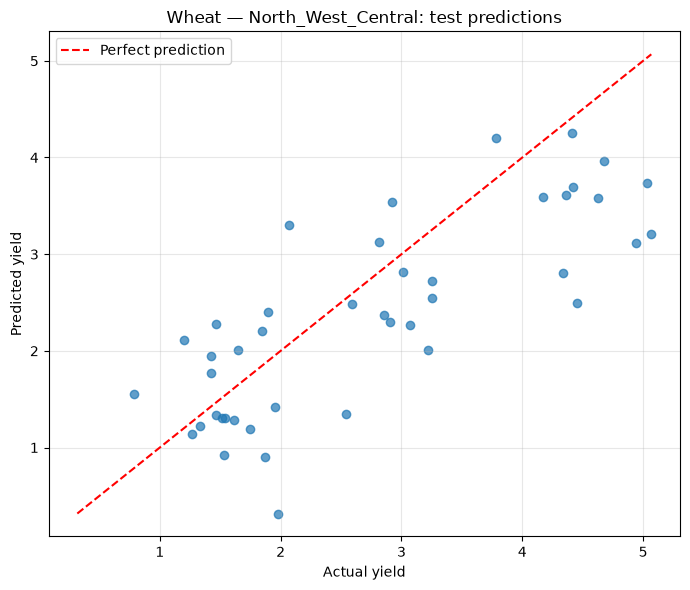

In [117]:
import matplotlib.pyplot as plt

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())

plt.figure(figsize=(7, 6))

plt.scatter(y_test, predictions, alpha=0.7)
plt.plot(
    [low, high], [low, high],
    "r--", label="Perfect prediction"
)

plt.xlabel("Actual yield")
plt.ylabel("Predicted yield")
plt.title("Wheat — North_West_Central: test predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.6 Check whether errors differ by state

An overall score can hide systematic errors for particular states. The next table groups the wheat test errors by state; a positive mean residual means actual yield was higher than predicted, indicating underprediction. The small number of test records per state means these patterns need cautious interpretation.

In [118]:
# Keep state and year alongside each test prediction
errors = test[["State", year_col, "Yield"]].copy()

errors["Predicted_Yield"] = predictions
errors["Residual"] = errors["Yield"] - errors["Predicted_Yield"]
errors["Absolute_Error"] = errors["Residual"].abs()

state_errors = (
    errors.groupby("State")
    .agg(
        Records=("Yield", "size"),
        Actual_Mean=("Yield", "mean"),
        Predicted_Mean=("Predicted_Yield", "mean"),
        Mean_Residual=("Residual", "mean"),
        MAE=("Absolute_Error", "mean")
    )
    .sort_values("MAE", ascending=False)
)

display(state_errors.round(3))

,Records,Actual_Mean,Predicted_Mean,Mean_Residual,MAE
State,,,,,
Punjab,4,4.714,3.469,1.245,1.245
Delhi,4,4.392,3.152,1.240,1.240
Uttar Pradesh,4,2.946,2.646,0.300,0.916
Uttarakhand,4,1.837,0.986,0.852,0.852
Haryana,4,4.462,3.945,0.517,0.728
Madhya Pradesh,4,2.723,2.126,0.597,0.597
Maharashtra,4,1.443,1.935,-0.493,0.554
Himachal Pradesh,4,1.488,2.026,-0.538,0.538
Gujarat,4,2.955,2.938,0.018,0.485


## 5. Case study: moong in East Northeast

### 5.1 Select and check the moong records

The second example uses Moong (Green Gram) in East Northeast and includes state identity alongside the same five numeric inputs. The next cell selects the records, treats infinite values as missing, and checks that enough years are available. Including state lets the model represent persistent differences between states.

In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder


# 1. Select moong records
moong_features = [
    "Annual_Rainfall",
    "Fertilizer_per_area",
    "Pesticide_per_area",
    "Mean_Temperature",
    "Relative_Humidity"
]

moong_year_col = "Crop_Year"
moong_columns = moong_features + ["State"]

moong_data = eda.loc[
    (eda["Crop"] == "Moong(Green Gram)") &
    (eda["Region"] == "East_Northeast")
].copy()

moong_data[moong_features + ["Yield"]] = (
    moong_data[moong_features + ["Yield"]]
    .replace([np.inf, -np.inf], np.nan)
)

moong_data = moong_data.dropna(
    subset=[moong_year_col, "State", "Yield"]
)

moong_years = np.array(
    sorted(moong_data[moong_year_col].unique())
)

if len(moong_years) < 5:
    raise ValueError(
        "Too few usable years for this training/validation/test setup. "
        "Check the crop name, region and available years."
    )


### 5.2 Reserve the latest years for testing

The next cell reserves 2011?2014 and keeps 1997?2010 for training and validation. This gives 152 training records and 50 test records across eight states in the selected dataset. Keeping years together prevents observations from the same year appearing on both sides of a split.

In [120]:
# 2. Reserve the latest 20% of years for testing
moong_cut = int(len(moong_years) * 0.8)

moong_train_years = moong_years[:moong_cut]
moong_test_years = moong_years[moong_cut:]

moong_train = moong_data[
    moong_data[moong_year_col].isin(moong_train_years)
].copy()

moong_test = moong_data[
    moong_data[moong_year_col].isin(moong_test_years)
].copy()

print("Moong(Green Gram) — East_Northeast")
print(
    f"Training: {len(moong_train)} records, "
    f"{moong_train_years[0]}–{moong_train_years[-1]}"
)
print(
    f"Testing: {len(moong_test)} records, "
    f"{moong_test_years[0]}–{moong_test_years[-1]}"
)
print("States:", moong_data["State"].nunique())


Moong(Green Gram) — East_Northeast
Training: 152 records, 1997–2010
Testing: 50 records, 2011–2014
States: 8


### 5.3 Define the model, scores and state-average baseline

The next cell defines a linear model that fills missing numeric inputs and represents state names as indicator columns. Its baseline predicts each state's historical average, falling back to the overall training average for an unseen state. This is a stronger comparison than a single regional average because both methods account for state differences.

In [121]:
# 3. Define preprocessing and linear regression
moong_preprocessor = ColumnTransformer([
    (
        "numeric",
        SimpleImputer(strategy="median"),
        moong_features
    ),
    (
        "state",
        OneHotEncoder(drop="first", handle_unknown="ignore"),
        ["State"]
    )
])

moong_pipeline = make_pipeline(
    moong_preprocessor,
    LinearRegression()
)


# Helper: evaluation metrics
def moong_scores(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": (
            r2_score(actual, predicted)
            if len(actual) >= 2 else np.nan
        )
    }


# Helper: historical state-average predictions
def moong_baseline(fitting_data, evaluation_data):
    state_means = fitting_data.groupby("State")["Yield"].mean()

    return (
        evaluation_data["State"]
        .map(state_means)
        .fillna(fitting_data["Yield"].mean())
        .to_numpy()
    )


### 5.4 Validate on three successive time periods

The next cell repeatedly trains on earlier years and validates on the next group of years within 1997?2010. Comparing three periods shows whether an apparent improvement is consistent over time before looking at the reserved test years. A warning about an unknown state means it was absent from that fold's training data; the encoder handles it without a learned state-specific adjustment.

In [122]:
# 4. Validate on three chronological splits within training data
moong_cv = TimeSeriesSplit(n_splits=3)
moong_cv_rows = []

for fold, (fit_idx, val_idx) in enumerate(
    moong_cv.split(moong_train_years), start=1
):
    fold_train = moong_train[
        moong_train[moong_year_col].isin(
            moong_train_years[fit_idx]
        )
    ]

    fold_val = moong_train[
        moong_train[moong_year_col].isin(
            moong_train_years[val_idx]
        )
    ]

    fold_model = clone(moong_pipeline)
    fold_model.fit(
        fold_train[moong_columns],
        fold_train["Yield"]
    )

    fold_predictions = {
        "State mean baseline": moong_baseline(fold_train, fold_val),
        "Linear regression + State": fold_model.predict(
            fold_val[moong_columns]
        )
    }

    for name, predicted in fold_predictions.items():
        moong_cv_rows.append({
            "Fold": fold,
            "Validation_years": (
                f"{moong_train_years[val_idx][0]}–"
                f"{moong_train_years[val_idx][-1]}"
            ),
            "Model": name,
            **moong_scores(fold_val["Yield"], predicted)
        })

moong_cv_results = pd.DataFrame(moong_cv_rows)

print("\nValidation results:")
display(moong_cv_results.round(3))

print("\nAverage validation scores across folds:")
display(
    moong_cv_results
    .groupby("Model")[["MAE", "RMSE", "R²"]]
    .mean()
    .round(3)
)



Validation results:


c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Fold,Validation_years,Model,MAE,RMSE,R²
0,1,2002–2004,State mean baseline,0.115,0.178,0.652
1,1,2002–2004,Linear regression + State,0.191,0.247,0.332
2,2,2005–2007,State mean baseline,0.090,0.147,0.752
3,2,2005–2007,Linear regression + State,0.106,0.169,0.672
4,3,2008–2010,State mean baseline,0.106,0.163,0.458
5,3,2008–2010,Linear regression + State,0.104,0.166,0.441



Average validation scores across folds:


,MAE,RMSE,R²
Model,,,
Linear regression + State,0.134,0.194,0.482
State mean baseline,0.104,0.163,0.621


### 5.5 Compare both methods on the reserved years

The next cell fits the model on all training years and evaluates it on 2011?2014. Read this table alongside validation: the recorded average validation MAE favours the state baseline (0.104 versus 0.134), so an improvement on the final test period alone is not evidence of consistently better performance.

In [123]:
# 5. Fit on all training years and evaluate on reserved test years
moong_model = clone(moong_pipeline)
moong_model.fit(
    moong_train[moong_columns],
    moong_train["Yield"]
)

moong_predictions = moong_model.predict(
    moong_test[moong_columns]
)

moong_baseline_predictions = moong_baseline(
    moong_train, moong_test
)

moong_test_results = pd.DataFrame([
    {
        "Model": "State mean baseline",
        **moong_scores(
            moong_test["Yield"],
            moong_baseline_predictions
        )
    },
    {
        "Model": "Linear regression + State",
        **moong_scores(
            moong_test["Yield"],
            moong_predictions
        )
    }
])

print("\nReserved test results:")
display(moong_test_results.round(3))



Reserved test results:


,Model,MAE,RMSE,R²
0,State mean baseline,0.102,0.130,0.643
1,Linear regression + State,0.079,0.104,0.773


### 5.6 Inspect the moong predictions visually

On the reserved test period, the recorded MAE falls from 0.102 for the state baseline to 0.079 for linear regression. The next chart shows the individual predictions against observed yields using the same diagonal reference as the wheat example. These scores concern a different crop and should not be compared directly with the wheat error values.

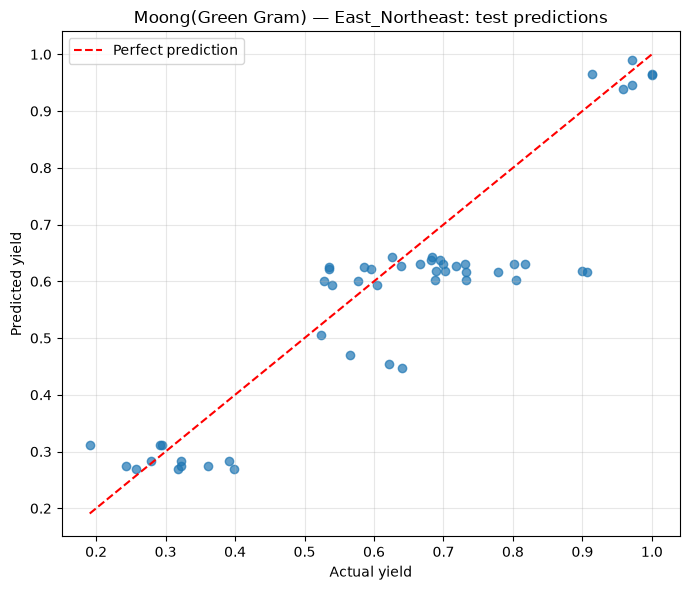

In [124]:
# 6. Plot actual versus predicted test yields
moong_actual = moong_test["Yield"].to_numpy()

moong_low = min(moong_actual.min(), moong_predictions.min())
moong_high = max(moong_actual.max(), moong_predictions.max())

plt.figure(figsize=(7, 6))
plt.scatter(moong_actual, moong_predictions, alpha=0.7)
plt.plot(
    [moong_low, moong_high],
    [moong_low, moong_high],
    "r--",
    label="Perfect prediction"
)
plt.xlabel("Actual yield")
plt.ylabel("Predicted yield")
plt.title("Moong(Green Gram) — East_Northeast: test predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Test whether the case-study gains generalise

### 6.1 Set the scope of the broader comparison

The next analysis includes crop and region combinations with at least 60 records and eight distinct years, using the same data through 2014. Each state and season combination is treated as a separate forecasting unit, even though some result labels abbreviate this as ?State?. The settings use every second eligible test year to reduce runtime; this is a selected evaluation schedule rather than a test of every year.

In [125]:
FEATURES = ["Annual_Rainfall", "Fertilizer_per_area", "Pesticide_per_area",
            "Mean_Temperature", "Relative_Humidity"]
YEAR = "Crop_Year"
MIN_ROWS, MIN_YEARS, MIN_TRAIN_YEARS = 60, 8, 5
N_BOOT = 2000
TREND_ALPHA = 0.01   # near-unregularised trend baseline, so the baseline is not handicapped
N_TREES = 60        # forest size; the random forest is the slowest part
YEAR_STRIDE = 2     # forecast every 2nd year; set to 1 for the full run
rng = np.random.default_rng(42)

# ------------------------------------------------------------------ data
d = eda.copy()
d[FEATURES + ["Yield"]] = d[FEATURES + ["Yield"]].replace([np.inf, -np.inf], np.nan)
d = d.dropna(subset=[YEAR, "State", "Yield"])
d["Season"] = d["Season"].astype(str).str.strip() if "Season" in d else "All"
d["Unit"] = d["State"] + "|" + d["Season"]          # state-season = forecasting unit
groups = [(k, g.reset_index(drop=True)) for k, g in d.groupby(["Region", "Crop"])
          if len(g) >= MIN_ROWS and g[YEAR].nunique() >= MIN_YEARS]
print(f"{len(groups)} region-crop pairs, {sum(len(g) for _, g in groups)} records")


102 region-crop pairs, 12880 records


### 6.2 Define simple and more complex prediction methods

The next cell defines historical-average, last-observed-value and time-trend baselines, plus models using the five inputs. A random forest combines many decision trees to represent relationships that need not follow a straight line; a second version models what remains after a time trend is removed. Shuffled-input controls deliberately mix up input rows within each state and season to check whether the original alignment adds useful information.

In [126]:
# ---------------------------------------------------------------- models
def ridge(num_cols, alpha=1.0):
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["Unit"])])
    return make_pipeline(pre, Ridge(alpha=alpha))


def forest(num_cols):
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["Unit"])])
    return make_pipeline(pre, RandomForestRegressor(
        n_estimators=N_TREES, min_samples_leaf=3, max_features=0.5,
        random_state=0, n_jobs=-1))


def forest_detrended(fit, ev, shuffle=False):
    """Forest fitted to what state + trend cannot explain, so it needs no extrapolation."""
    if shuffle:
        fit, ev = shuffled(fit), shuffled(ev)
    trend = ridge([YEAR], TREND_ALPHA).fit(fit[[YEAR, "Unit"]], fit["Yield"])
    resid = fit["Yield"] - trend.predict(fit[[YEAR, "Unit"]])
    f = forest(FEATURES).fit(fit[FEATURES + ["Unit"]], resid)
    return trend.predict(ev[[YEAR, "Unit"]]) + f.predict(ev[FEATURES + ["Unit"]])


def unit_mean(fit, ev):
    m = fit.groupby("Unit")["Yield"].mean()
    return ev["Unit"].map(m).fillna(fit["Yield"].mean()).to_numpy()


def unit_last(fit, ev):
    m = fit.sort_values(YEAR).groupby("Unit")["Yield"].last()
    return ev["Unit"].map(m).fillna(fit["Yield"].mean()).to_numpy()


def shuffled(df):
    """Control: permute the feature rows within each unit, destroying any real signal."""
    out = df.copy()
    cols = [out.columns.get_loc(c) for c in FEATURES]
    for idx in out.groupby("Unit").indices.values():
        out.iloc[idx, cols] = out.iloc[rng.permutation(idx), cols].to_numpy()
    return out


def fit_predict(model, fit, ev, cols, shuffle=False):
    if shuffle:
        fit, ev = shuffled(fit), shuffled(ev)
    return model.fit(fit[cols + ["Unit"]], fit["Yield"]).predict(ev[cols + ["Unit"]])


M_MEAN, M_LAST = "State mean", "State last value"
M_TREND, M_FEAT = "State + trend", "State + trend + features"
M_RF, M_CTRL = "Random forest (all features)", "Control: shuffled features"
M_RFD = "Random forest on detrended residual"
M_RFDC = "Control: detrended forest, shuffled features"
BASELINES = [M_MEAN, M_LAST, M_TREND]


### 6.3 Train on earlier years and predict the next selected year

For each eligible test year, the next cell trains only on previous years, then records each method's errors on that year. Errors are divided by each crop and region combination's mean observed yield across its evaluation records, preventing large yield scales from dominating the comparison. This scaling summarises the evaluation and is not a model input; the pooled score still gives more weight to combinations with more records.

In [127]:
# ---------------------------------- rolling-origin forecasts (train < t, predict t)
import time
start = time.time()
parts = []
for i, ((region, crop), g) in enumerate(groups, 1):
    if i % 10 == 0:
        print(f"  {i}/{len(groups)} pairs done, {time.time() - start:.0f}s")
    for t in np.sort(g[YEAR].unique())[MIN_TRAIN_YEARS::YEAR_STRIDE]:
        fit = g[g[YEAR] < t].reset_index(drop=True)
        ev = g[g[YEAR] == t].reset_index(drop=True)
        preds = {
            M_MEAN: unit_mean(fit, ev),
            M_LAST: unit_last(fit, ev),
            M_TREND: fit_predict(ridge([YEAR], TREND_ALPHA), fit, ev, [YEAR]),
            M_FEAT: fit_predict(ridge(FEATURES + [YEAR]), fit, ev, FEATURES + [YEAR]),
            M_RF: fit_predict(forest(FEATURES + [YEAR]), fit, ev, FEATURES + [YEAR]),
            M_CTRL: fit_predict(ridge(FEATURES + [YEAR]), fit, ev, FEATURES + [YEAR], True),
            M_RFD: forest_detrended(fit, ev),
            M_RFDC: forest_detrended(fit, ev, shuffle=True),
        }
        for name, p in preds.items():
            parts.append(pd.DataFrame({"Region": region, "Crop": crop, "Year": t,
                                       "Model": name, "Actual": ev["Yield"], "Pred": p}))
res = pd.concat(parts, ignore_index=True)
res["AbsErr"] = (res["Actual"] - res["Pred"]).abs()
res["SqErr"] = (res["Actual"] - res["Pred"]) ** 2
# Scale-free error: divide by each region-crop pair's mean yield so that large-scale
# crops (e.g. coconut) don't dominate the pooled numbers.
scale = res[res["Model"] == M_MEAN].groupby(["Region", "Crop"])["Actual"].mean().rename("Scale")
res = res.join(scale, on=["Region", "Crop"])
res["NAE"] = res["AbsErr"] / res["Scale"]
res["NSE"] = res["SqErr"] / res["Scale"] ** 2
n_pred = res["Model"].eq(M_MEAN).sum()
print(f"{n_pred} out-of-sample forecasts per model")


  10/102 pairs done, 21s
  20/102 pairs done, 44s
  30/102 pairs done, 67s
  40/102 pairs done, 89s
  50/102 pairs done, 110s
  60/102 pairs done, 130s
  70/102 pairs done, 150s
  80/102 pairs done, 171s
  90/102 pairs done, 194s


c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  global _threadpool_controller
c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  global _threadpool_controller
c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  global _threadpool_controller
c:\Users\maxi

  100/102 pairs done, 214s


c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  global _threadpool_controller
c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  global _threadpool_controller
c:\Users\maxim\anaconda3\envs\engg2112\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  global _threadpool_controller
c:\Users\maxi

5314 out-of-sample forecasts per model


### 6.4 Estimate uncertainty by resampling whole years

Errors from the same year may share weather or other influences, so the next cell resamples whole years together 2,000 times. This bootstrap procedure estimates how sensitive comparisons are to the observed years. It also identifies the best simple baseline on these evaluation results; that choice is descriptive and is not independently confirmed on a new test period.

In [128]:
# ------------------------------- year-block bootstrap (errors in one year are correlated)
S = res.pivot_table(index="Year", columns="Model", values="NAE", aggfunc="sum")
N = res[res["Model"] == M_MEAN].groupby("Year").size().reindex(S.index)
boot_idx = rng.integers(0, len(S), size=(N_BOOT, len(S)))


def boot_mae(model):
    return S[model].to_numpy()[boot_idx].sum(1) / N.to_numpy()[boot_idx].sum(1)


mae = {m: S[m].sum() / N.sum() for m in S.columns}
rmse = res.groupby("Model")["NSE"].mean().pow(0.5)
best_simple = min(BASELINES, key=mae.get)


### 6.5 Compare the overall error scores

The next table ranks the methods using normalised MAE and RMSE, where smaller values mean better predictions. ?MAE vs state mean? is a fractional change: -0.123 means about 12.3% less error than the historical-average baseline. Because the scores are normalised, they are relative errors rather than physical yield units.

In [129]:
# -------------------------------------------------- 1. forecast accuracy ladder
ladder = pd.DataFrame({"Norm. MAE": pd.Series(mae), "Norm. RMSE": rmse})
ladder["MAE vs state mean"] = ladder["Norm. MAE"] / mae[M_MEAN] - 1
order = [M_MEAN, M_LAST, M_TREND, M_FEAT, M_RF, M_RFD, M_CTRL, M_RFDC]
print("\n1. Out-of-sample accuracy, scale-free (error / pair mean yield; negative % = better than state mean):")
display(ladder.loc[order].round(3))
print(f"Best simple baseline: {best_simple}")



1. Out-of-sample accuracy, scale-free (error / pair mean yield; negative % = better than state mean):


,Norm. MAE,Norm. RMSE,MAE vs state mean
State mean,0.238,1.030,0.000
State last value,0.209,1.005,-0.123
State + trend,0.253,1.107,0.061
State + trend + features,0.408,1.499,0.714
Random forest (all features),0.320,1.188,0.346
Random forest on detrended residual,0.253,1.119,0.064
Control: shuffled features,0.472,1.986,0.981
"Control: detrended forest, shuffled features",0.264,1.113,0.109


Best simple baseline: State last value


### 6.6 Check the size and consistency of improvements

The next table compares methods on the same observations and gives a 95% bootstrap interval for the difference in normalised MAE. A positive gain favours the model; an interval crossing zero means this procedure does not detect a clear difference. The following win rates show how often a model improves within individual crop and region combinations, which can differ from its pooled performance.

In [130]:
# ------------------------------------------------- 2. paired tests with CIs
def compare(model, ref, question):
    gain = mae[ref] - mae[model]                       # positive = model better
    boots = boot_mae(ref) - boot_mae(model)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    verdict = ("model better" if lo > 0 else "model worse" if hi < 0
               else "no detectable difference")
    return {"Question": question, "Model": model, "Reference": ref,
            "Norm. MAE gain": gain, "Gain %": 100 * gain / mae[ref],
            "CI low": lo, "CI high": hi, "Verdict": verdict}


tests = pd.DataFrame([
    compare(M_FEAT, M_TREND, "Do weather/inputs add anything to state + trend?"),
    compare(M_FEAT, M_CTRL, "Are the features better than shuffled noise?"),
    compare(M_RF, M_TREND, "Does a nonlinear ML model beat state + trend?"),
    compare(M_RF, best_simple, "Does ML beat the best simple baseline?"),
    compare(M_RFD, M_TREND, "Does a detrended forest beat state + trend?"),
    compare(M_RFD, best_simple, "Does a detrended forest beat the best simple baseline?"),
    compare(M_RFD, M_RFDC, "Does the detrended forest's gain come from the features (vs shuffled)?"),
])
print("\n2. Paired comparisons (95% year-block bootstrap CI; gain = reference norm. MAE - model norm. MAE):")
display(tests.round(4))

# per-pair win rate: in how many region-crop pairs does the model beat the reference?
pm = res.pivot_table(index=["Region", "Crop"], columns="Model", values="AbsErr", aggfunc="mean")
print("\nShare of region-crop pairs where the model beats the reference:")
for model, ref in [(M_FEAT, M_TREND), (M_RF, M_TREND), (M_RF, best_simple),
                   (M_RFD, M_TREND), (M_RFD, best_simple)]:
    print(f"  {model} vs {ref}: {(pm[model] < pm[ref]).mean():.0%} of {len(pm)} pairs")



2. Paired comparisons (95% year-block bootstrap CI; gain = reference norm. MAE - model norm. MAE):


,Question,Model,Reference,Norm. MAE gain,Gain %,CI low,CI high,Verdict
0,Do weather/inputs add anything to state + trend?,State + trend + features,State + trend,-0.1556,-61.5896,-0.2360,-0.0928,model worse
1,Are the features better than shuffled noise?,State + trend + features,Control: shuffled features,0.0634,13.4498,-0.0290,0.1621,no detectable difference
2,Does a nonlinear ML model beat state + trend?,Random forest (all features),State + trend,-0.0679,-26.8638,-0.1344,-0.0264,model worse
3,Does ML beat the best simple baseline?,Random forest (all features),State last value,-0.1116,-53.4326,-0.1734,-0.0641,model worse
4,Does a detrended forest beat state + trend?,Random forest on detrended residual,State + trend,-0.0007,-0.2709,-0.0109,0.0053,no detectable difference
5,Does a detrended forest beat the best simple b...,Random forest on detrended residual,State last value,-0.0444,-21.2704,-0.0792,-0.0130,model worse
6,Does the detrended forest's gain come from the...,Random forest on detrended residual,"Control: detrended forest, shuffled features",0.0108,4.0900,0.0044,0.0173,model better



Share of region-crop pairs where the model beats the reference:
  State + trend + features vs State + trend: 14% of 102 pairs
  Random forest (all features) vs State + trend: 27% of 102 pairs
  Random forest (all features) vs State last value: 16% of 102 pairs
  Random forest on detrended residual vs State + trend: 70% of 102 pairs
  Random forest on detrended residual vs State last value: 39% of 102 pairs


### 6.7 Look for remaining input?yield associations

The next cell removes estimated state and season differences and a linear time trend before measuring input?yield correlations. This asks whether the inputs still move with yield after those broad patterns are accounted for. The p-values are exploratory: many comparisons are made without a multiple-testing correction, and repeated observations may be dependent, so the reported shares should not be treated as confirmed discoveries or causal effects.

In [131]:
# ------- 3. do features carry signal after removing state/season level and trend?
cor_rows = []
for (region, crop), g in groups:
    X = np.column_stack([pd.get_dummies(g["Unit"], dtype=float).to_numpy(), g[YEAR] - g[YEAR].mean()])

    def resid(v):
        v = pd.Series(v).fillna(pd.Series(v).median()).to_numpy(float)
        return v - X @ np.linalg.lstsq(X, v, rcond=None)[0]

    ry, dof = resid(g["Yield"]), len(g) - X.shape[1] - 1
    for f in FEATURES:
        rf = resid(g[f])
        if dof < 10 or rf.std() < 1e-9 or ry.std() < 1e-9:
            continue
        r = np.corrcoef(rf, ry)[0, 1]
        p = 2 * stats.t.sf(abs(r) * np.sqrt(dof / (1 - r ** 2)), dof)
        cor_rows.append({"Region": region, "Crop": crop, "Feature": f, "r": r, "p": p})
cors = pd.DataFrame(cor_rows)
cor_summary = cors.groupby("Feature").agg(
    pairs=("r", "size"), median_abs_r=("r", lambda s: s.abs().median()),
    share_p_below_05=("p", lambda s: (s < 0.05).mean()))
print("\n3. Partial correlation with yield after removing state/season effects and trend")
print("   (pure chance would give ~5% of pairs with p < 0.05):")
display(cor_summary.round(3))



3. Partial correlation with yield after removing state/season effects and trend
   (pure chance would give ~5% of pairs with p < 0.05):


,pairs,median_abs_r,share_p_below_05
Feature,,,
Annual_Rainfall,102,0.085,0.118
Fertilizer_per_area,102,0.085,0.127
Mean_Temperature,102,0.108,0.157
Pesticide_per_area,102,0.102,0.206
Relative_Humidity,102,0.114,0.235


### 6.8 Summarise accuracy and remaining associations visually

The left panel shows each method's percentage error change relative to the historical-average baseline, with bootstrap uncertainty bars; values to the left of zero indicate lower error. The right panel shows the spread of correlations remaining after state, season and time patterns are removed. Together, they distinguish predictive performance from the presence of an association.

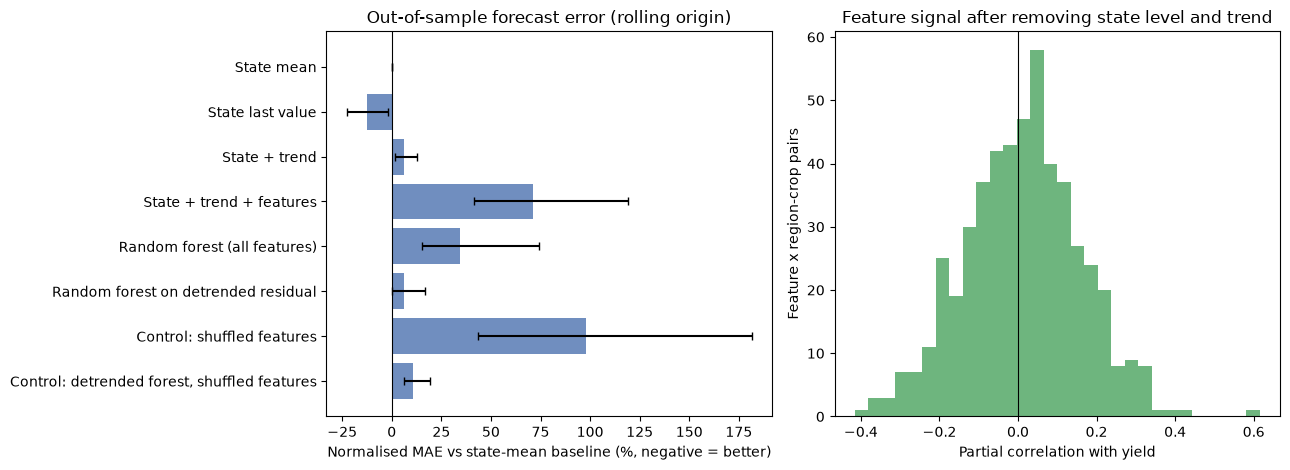

In [132]:
# -------------------------------------------------------------------- figure
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
rel, err = [], []
for m in order:
    b = boot_mae(m) / boot_mae(M_MEAN) - 1
    rel.append(mae[m] / mae[M_MEAN] - 1)
    err.append(np.percentile(b, [2.5, 97.5]))
rel, err = np.array(rel), np.array(err)
ypos = np.arange(len(order))
ax[0].barh(ypos, rel * 100, color="#4C72B0", alpha=0.8)
ax[0].errorbar(rel * 100, ypos, xerr=[(rel - err[:, 0]) * 100, (err[:, 1] - rel) * 100],
               fmt="none", ecolor="black", capsize=3)
ax[0].set_yticks(ypos)
ax[0].set_yticklabels(order)
ax[0].invert_yaxis()
ax[0].axvline(0, color="k", lw=0.8)
ax[0].set_xlabel("Normalised MAE vs state-mean baseline (%, negative = better)")
ax[0].set_title("Out-of-sample forecast error (rolling origin)")
ax[1].hist(cors["r"], bins=30, color="#55A868", alpha=0.85)
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_xlabel("Partial correlation with yield")
ax[1].set_ylabel("Feature x region-crop pairs")
ax[1].set_title("Feature signal after removing state level and trend")
plt.tight_layout()
plt.show()


## 7. What can we conclude?

The two case studies show that the selected inputs can improve predictions in particular test periods. Wheat test MAE falls from 1.115 to 0.718 against a regional-average baseline, and moong test MAE falls from 0.102 to 0.079 against a state-average baseline. However, the moong model performs worse on average across the earlier validation periods, so its improvement is not consistent over time.

The broader evaluation covers **102 crop and region combinations and 5,314 predictions per method**. Its best simple baseline is the last observed yield for each state and season, with normalised MAE of about **0.209**, compared with **0.238** for the historical average. The random forest scores about **0.319**, and the forest applied after removing a time trend scores about **0.253**. Neither beats the last-value baseline overall; the reported bootstrap comparisons also favour that baseline over both forests.

The detrended forest does improve over its shuffled-input control, suggesting the aligned inputs contain some predictive information in this experiment. That improvement does not establish that the inputs cause yield changes or that the tested complex models are more useful than the strongest simple reference. **For this dataset and evaluation, past yield remains the strongest overall starting point among the methods tested.**

### Limits of the evidence

These are retrospective predictions using the observed inputs for the year being predicted. Full-year weather and agricultural inputs may not be available when a real forecast is needed, so the experiment does not establish performance for forecasts made before harvest. One weather location per state and calendar-year averages also provide only approximate growing conditions, particularly for seasons crossing calendar years.

The case studies were chosen after exploring records through 2014, including their eventual test years, and the broader evaluation reuses that period. It therefore provides exploratory evidence rather than a fully untouched final assessment. The bootstrap intervals describe variation under the chosen resampling scheme; they do not account for every source of uncertainty, model selection or all comparisons made.